In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('../src/')

In [10]:
import os
import warnings
import rioxarray
import rasterio
import numpy as np
import xarray as xr
import pandas as pd
import geopandas as gpd
from tqdm import tqdm

import matplotlib.pyplot as plt

from shapely import geometry
#from landsat_get import Landsat
from rasterio.plot import show
from itertools import combinations
from dnbr import calculate_dnbr, calculate_nbr
from rasterio.enums import Resampling

from xrspatial.multispectral import nbr

In [11]:
mtbs = gpd.read_file("/mnt/sherlock/prescribed_data/geoms/mtbs_perims_DD/")
mtbs["Ig_Date"] = pd.to_datetime(mtbs["Ig_Date"])
mtbs_ca = mtbs[(mtbs.Event_ID.str.contains("CA")) & (mtbs.Incid_Type == "Wildfire")]

mtbs_ca_meters = mtbs_ca.to_crs(3310)

mtbs_ca_buffers = mtbs_ca.copy()
mtbs_ca_buffers["geometry"] = (
    mtbs_ca_meters
    .buffer(180)
    .to_crs(mtbs_ca.crs)
)

In [12]:
from pathlib import Path

dnbr_files = list(Path("/mnt/sherlock/prescribed_data/processed/dnbr_landsat_c2_l2_buf/").rglob("*.tif"))
dnbr_events = [d.name.split(".")[0] for d in dnbr_files]

In [17]:
mtbs_ca.sort_values("BurnBndAc", ascending=False)

,Event_ID,irwinID,Incid_Name,Incid_Type,Map_ID,Map_Prog,Asmnt_Type,BurnBndAc,BurnBndLat,BurnBndLon,...,Perim_ID,dNBR_offst,dNBR_stdDv,NoData_T,IncGreen_T,Low_T,Mod_T,High_T,Comment,geometry
28876,CA3966012280920200817,EE343B88-0ADB-4C25-B744-6B4CE9DCC6DA,AUGUST COMPLEX,Wildfire,10021108,MTBS,Extended,1068802,39.94,-123.03,...,804503220201019,37,34,-970,-150,110,309,550,"CA4012512307320200818, CA4008712298420200819, ...","POLYGON ((-122.86087 39.49303, -122.86084 39.4..."
27583,CA3924012311020180727,25B938AB-3047-4D7B-ADE3-FD752F156F7C,RANCH,Wildfire,10014566,MTBS,Extended,427048,39.269,-122.775,...,NaN,-24,36,-970,-150,55,302,575,Used modified geomac perimeter.,"POLYGON ((-122.68854 39.51925, -122.68845 39.5..."
28893,CA3742412156820200816,871C357C-444E-437E-AD4D-EBDAF39C3AD6,SCU LIGHTNING COMPLEX,Wildfire,10021184,MTBS,Initial,405787,37.493,-121.5,...,NaN,52,43,-970,-150,90,350,640,4-4 fire is included in this complex.,"MULTIPOLYGON (((-121.86486 37.51712, -121.8644..."
28702,CA3720111927220200905,33CBB9DC-6983-4F47-B821-9C9A6CAC381D,CREEK,Wildfire,10020469,MTBS,Extended,381441,37.317,-119.214,...,NaN,36,36,-970,-150,65,324,610,NaN,"POLYGON ((-119.39124 37.15000, -119.39144 37.1..."
28835,CA4009112093120200817,6701B25B-7005-4C57-8577-96E15AC213C4,NORTH COMPLEX,Wildfire,10020999,MTBS,Extended,316556,39.725,-121.127,...,804403220201012,29,22,-970,-150,90,328,600,Complex includes Baer and Claremont fires.,"MULTIPOLYGON (((-121.42921 39.54718, -121.4286..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3230,CA3311711533419901106,NaN,YOCUM,Wildfire,10006542,MTBS,Initial,1006,33.109,-115.341,...,NaN,-4,23,-970,-150,50,9999,9999,NaN,"POLYGON ((-115.34236 33.12319, -115.34153 33.1..."
2166,CA3621211899819880622,NaN,LINDSAY,Wildfire,6337,MTBS,Initial (SS),1005,36.212,-118.998,...,NaN,-9999,-9999,9999,9999,-120,-9999,-9999,NaN,"POLYGON ((-118.98662 36.19518, -118.98754 36.1..."
755,CA3764511959919850728,NaN,LOST BEAR,Wildfire,10011461,MTBS,Extended,1002,37.645,-119.598,...,NaN,-1,32,-970,-150,30,210,430,"Mapped fire using NPS offset, thresholds, and ...","POLYGON ((-119.60633 37.63423, -119.60724 37.6..."
25018,CA3436911855620160709,B5974B39-3DD3-40FD-A511-0ED43DB719A4,SAGE,Wildfire,10005366,MTBS,Initial,1002,34.366,-118.574,...,NaN,15,17,-970,-150,50,350,500,NaN,"POLYGON ((-118.59000 34.36590, -118.59001 34.3..."


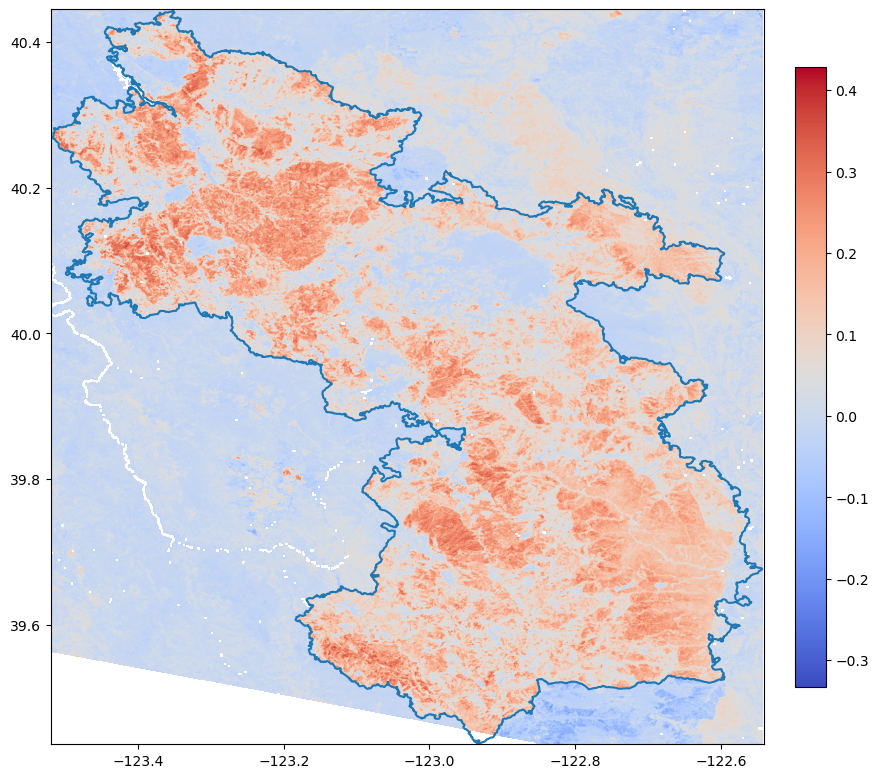

In [20]:
from mpl_toolkits.axes_grid1 import make_axes_locatable


event_id = "CA3966012280920200817"
file_path = f"/mnt/sherlock/prescribed_data/processed/dnbr_landsat_c2_l2_buf/{event_id}.tif"

fig, ax = plt.subplots(figsize=(10, 15))
#mtbs_ca_buffers[mtbs_ca_buffers.Event_ID == event_id].boundary.plot(ax=ax, color="red")
mtbs_ca[mtbs_ca.Event_ID == event_id].boundary.plot(ax=ax)


with rasterio.open(file_path) as src:
    data = src.read()
    plot = show(src, 
                ax=ax, 
                vmax=np.nanmax(data),
                vmin=np.nanmin(data),
                cmap="coolwarm")
   
    image_hidden = plot.get_images()[0]
    fig.colorbar(image_hidden,
                 ax=ax, fraction=0.04, pad=0.04)
    